# Καλώς ορίσατε στο Colab!

In [ ]:
# ============================================================
# CELL 1: Setup and Load
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set random seed for reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Load the dataset
df = pd.read_csv('diabetes.csv')

# Basic structure
print(f"Shape: {df.shape}")
print(f"\nColumns: {list(df.columns)}")

# Preview
print(f"\nFirst 5 rows:")
print(df.head())

# Data types
print(f"\nData types:")
print(df.dtypes)

# Target class distribution (check for class imbalance)
print(f"\nTarget distribution:")
print(df['Outcome'].value_counts())
print(f"\nPositive class rate: {df['Outcome'].mean()*100:.1f}%")

Shape: (768, 9)

Columns: ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

First 5 rows:
   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   
3            1       89             66             23       94  28.1   
4            0      137             40             35      168  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness   

In [ ]:
# ============================================================
# CELL 2: Detect hidden missing values
# ============================================================
# In this dataset, zeros in certain columns are biologically implausible
# (no living person has Glucose=0 or BMI=0). These are actually missing
# values encoded as 0. This is a well-known characteristic of the Pima
# Indians Diabetes Dataset (Smith et al., 1988).

# Statistical summary
print("Statistical summary:")
print(df.describe().round(2))

# Columns where 0 is biologically impossible
cols_with_hidden_missing = ['Glucose', 'BloodPressure', 'SkinThickness',
                             'Insulin', 'BMI']

print("\nHidden missing values (zeros that should be NaN):")
print("-" * 50)
for col in cols_with_hidden_missing:
    n_zeros = (df[col] == 0).sum()
    pct = n_zeros / len(df) * 100
    print(f"{col:20s}: {n_zeros:4d} zeros ({pct:5.1f}%)")

# Check for explicit NaN values (probably none in this dataset)
print(f"\nExplicit NaN values: {df.isna().sum().sum()}")

Statistical summary:
       Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin     BMI  \
count       768.00   768.00         768.00         768.00   768.00  768.00   
mean          3.85   120.89          69.11          20.54    79.80   31.99   
std           3.37    31.97          19.36          15.95   115.24    7.88   
min           0.00     0.00           0.00           0.00     0.00    0.00   
25%           1.00    99.00          62.00           0.00     0.00   27.30   
50%           3.00   117.00          72.00          23.00    30.50   32.00   
75%           6.00   140.25          80.00          32.00   127.25   36.60   
max          17.00   199.00         122.00          99.00   846.00   67.10   

       DiabetesPedigreeFunction     Age  Outcome  
count                    768.00  768.00   768.00  
mean                       0.47   33.24     0.35  
std                        0.33   11.76     0.48  
min                        0.08   21.00     0.00  
25%                  

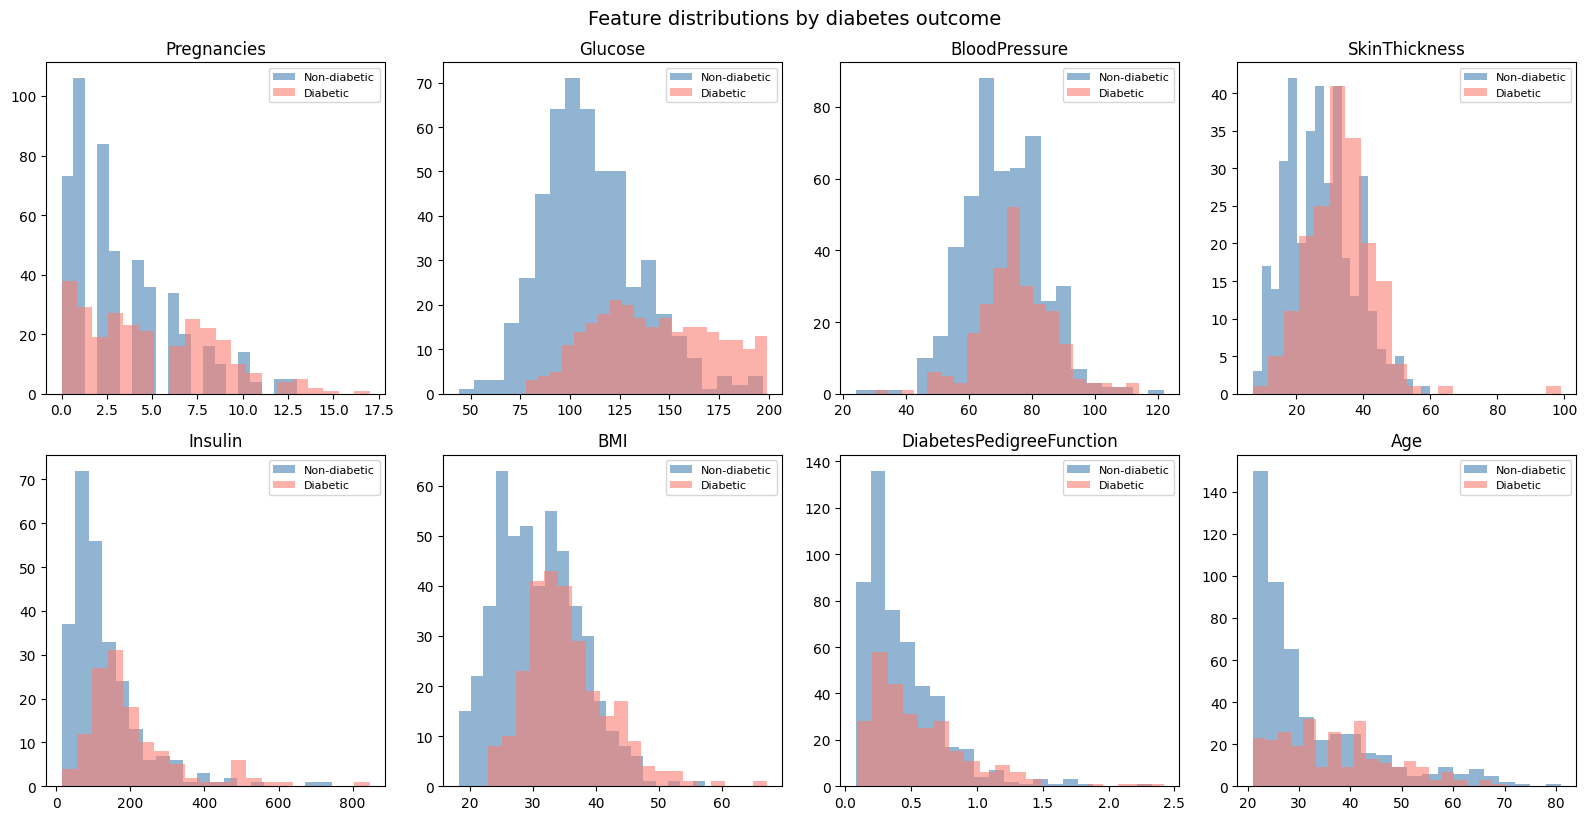

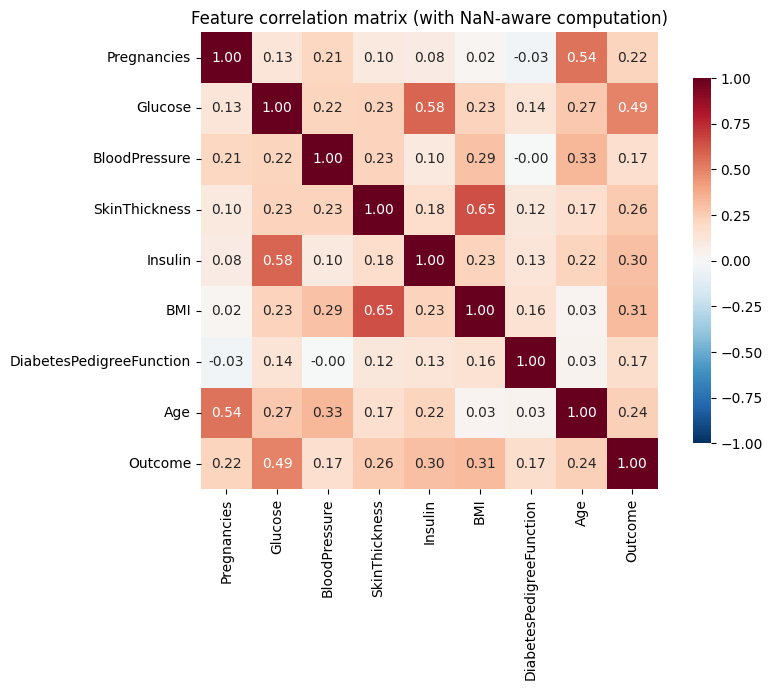


Correlation with Outcome (sorted):
Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64


In [ ]:
# ============================================================
# CELL 3: Exploratory data visualization
# ============================================================
# Replace biologically implausible zeros with NaN for accurate visualization
cols_with_hidden_missing = ['Glucose', 'BloodPressure', 'SkinThickness',
                             'Insulin', 'BMI']
df_viz = df.copy()
df_viz[cols_with_hidden_missing] = df_viz[cols_with_hidden_missing].replace(0, np.nan)

# --- Figure A: Feature distributions by outcome ---
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
features = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
            'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

for ax, feat in zip(axes.flatten(), features):
    for outcome, color, label in [(0, 'steelblue', 'Non-diabetic'),
                                   (1, 'salmon', 'Diabetic')]:
        subset = df_viz[df_viz['Outcome'] == outcome][feat].dropna()
        ax.hist(subset, bins=20, alpha=0.6, color=color, label=label)
    ax.set_title(feat)
    ax.set_xlabel('')
    ax.legend(fontsize=8)

plt.tight_layout()
plt.suptitle('Feature distributions by diabetes outcome', y=1.02, fontsize=14)
plt.savefig('fig_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

# --- Figure B: Correlation heatmap ---
plt.figure(figsize=(9, 7))
corr = df_viz.corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, vmin=-1, vmax=1, cbar_kws={'shrink': 0.8})
plt.title('Feature correlation matrix (with NaN-aware computation)')
plt.tight_layout()
plt.savefig('fig_correlation.png', dpi=150, bbox_inches='tight')
plt.show()

# Print the features most correlated with Outcome
print("\nCorrelation with Outcome (sorted):")
print(corr['Outcome'].drop('Outcome').sort_values(ascending=False).round(3))

In [ ]:
# ============================================================
# CELL 4: Preprocessing pipeline & train/test split
# ============================================================
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# --- Step 1: Encode biologically implausible zeros as NaN ---
# This must be done BEFORE splitting, because it is not a statistic
# learned from data, but a data-cleaning rule (zeros are known to
# represent missing values for these specific features).
cols_with_hidden_missing = ['Glucose', 'BloodPressure', 'SkinThickness',
                             'Insulin', 'BMI']
df_clean = df.copy()
df_clean[cols_with_hidden_missing] = df_clean[cols_with_hidden_missing].replace(0, np.nan)

# --- Step 2: Separate features (X) and target (y) ---
X = df_clean.drop('Outcome', axis=1)
y = df_clean['Outcome']

# --- Step 3: Stratified 80/20 train/test split ---
# Stratification preserves the class ratio (~35% positive) in both sets,
# which is important given the class imbalance.
# The test set will remain untouched until final evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=RANDOM_STATE
)

print(f"Training set: {X_train.shape[0]} samples")
print(f"  Positive class rate: {y_train.mean()*100:.1f}%")
print(f"Test set:     {X_test.shape[0]} samples")
print(f"  Positive class rate: {y_test.mean()*100:.1f}%")

# --- Step 4: Fit imputer and scaler on TRAINING data only ---
# This prevents data leakage: the test set must look like truly unseen data.
# Median imputation is preferred over mean for medical data because it is
# robust to outliers (e.g., an Insulin value of 846).
imputer = SimpleImputer(strategy='median')
scaler  = StandardScaler()

# Fit on train, transform both train and test
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed  = imputer.transform(X_test)

X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled  = scaler.transform(X_test_imputed)

# Keep scaled arrays as DataFrames for readability downstream
feature_names = X.columns.tolist()
X_train_scaled = pd.DataFrame(X_train_scaled, columns=feature_names)
X_test_scaled  = pd.DataFrame(X_test_scaled,  columns=feature_names)

print("\nImputation median values (learned from training data):")
for col, val in zip(feature_names, imputer.statistics_):
    print(f"  {col:25s}: {val:.2f}")

print("\nPreprocessing complete.")
print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_test_scaled  shape: {X_test_scaled.shape}")

Training set: 614 samples
  Positive class rate: 34.9%
Test set:     154 samples
  Positive class rate: 35.1%

Imputation median values (learned from training data):
  Pregnancies              : 3.00
  Glucose                  : 117.00
  BloodPressure            : 72.00
  SkinThickness            : 29.00
  Insulin                  : 125.00
  BMI                      : 32.40
  DiabetesPedigreeFunction : 0.38
  Age                      : 29.00

Preprocessing complete.
X_train_scaled shape: (614, 8)
X_test_scaled  shape: (154, 8)


In [ ]:
# ============================================================
# CELL 5: Train 3 models with 5-fold CV hyperparameter tuning
# ============================================================
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
import time

# XGBoost: install if not available in Colab (usually pre-installed)
try:
    from xgboost import XGBClassifier
except ImportError:
    import subprocess
    subprocess.check_call(['pip', 'install', '-q', 'xgboost'])
    from xgboost import XGBClassifier

# Use stratified 5-fold CV to preserve class ratio within each fold
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Scoring: ROC-AUC handles class imbalance and evaluates the probability
# ranking rather than a fixed threshold
scoring = 'roc_auc'

# ---------- Model 1: Logistic Regression ----------
print("Training Logistic Regression...")
t0 = time.time()
param_grid_lr = {
    'C': [0.01, 0.1, 1, 10, 100],          # inverse regularization strength
    'penalty': ['l2'],
    'class_weight': [None, 'balanced']
}
grid_lr = GridSearchCV(
    LogisticRegression(solver='liblinear', max_iter=1000, random_state=RANDOM_STATE),
    param_grid_lr, cv=cv, scoring=scoring, n_jobs=-1
)
grid_lr.fit(X_train_scaled, y_train)
time_lr = time.time() - t0
print(f"  Best CV ROC-AUC: {grid_lr.best_score_:.4f}")
print(f"  Best params: {grid_lr.best_params_}")
print(f"  Training time: {time_lr:.1f}s\n")

# ---------- Model 2: Random Forest ----------
print("Training Random Forest...")
t0 = time.time()
param_grid_rf = {
    'n_estimators': [100, 300],
    'max_depth': [None, 5, 10],
    'min_samples_split': [2, 5],
    'class_weight': [None, 'balanced']
}
grid_rf = GridSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid_rf, cv=cv, scoring=scoring, n_jobs=-1
)
grid_rf.fit(X_train_scaled, y_train)
time_rf = time.time() - t0
print(f"  Best CV ROC-AUC: {grid_rf.best_score_:.4f}")
print(f"  Best params: {grid_rf.best_params_}")
print(f"  Training time: {time_rf:.1f}s\n")

# ---------- Model 3: XGBoost ----------
# scale_pos_weight handles class imbalance: ratio of negatives to positives
neg_pos_ratio = (y_train == 0).sum() / (y_train == 1).sum()

print("Training XGBoost...")
t0 = time.time()
param_grid_xgb = {
    'n_estimators': [100, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1],
    'scale_pos_weight': [1, neg_pos_ratio]
}
grid_xgb = GridSearchCV(
    XGBClassifier(
        random_state=RANDOM_STATE,
        eval_metric='logloss',
        use_label_encoder=False,
        n_jobs=-1
    ),
    param_grid_xgb, cv=cv, scoring=scoring, n_jobs=-1
)
grid_xgb.fit(X_train_scaled, y_train)
time_xgb = time.time() - t0
print(f"  Best CV ROC-AUC: {grid_xgb.best_score_:.4f}")
print(f"  Best params: {grid_xgb.best_params_}")
print(f"  Training time: {time_xgb:.1f}s\n")

# ---------- Summary ----------
print("=" * 55)
print("Cross-validated ROC-AUC (mean over 5 folds):")
print("=" * 55)
print(f"  Logistic Regression: {grid_lr.best_score_:.4f}")
print(f"  Random Forest:       {grid_rf.best_score_:.4f}")
print(f"  XGBoost:             {grid_xgb.best_score_:.4f}")

Training Logistic Regression...
  Best CV ROC-AUC: 0.8451
  Best params: {'C': 0.1, 'class_weight': 'balanced', 'penalty': 'l2'}
  Training time: 8.5s

Training Random Forest...
  Best CV ROC-AUC: 0.8408
  Best params: {'class_weight': None, 'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 100}
  Training time: 69.4s

Training XGBoost...
  Best CV ROC-AUC: 0.8251
  Best params: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'scale_pos_weight': 1}
  Training time: 11.6s

Cross-validated ROC-AUC (mean over 5 folds):
  Logistic Regression: 0.8451
  Random Forest:       0.8408
  XGBoost:             0.8251


/usr/local/lib/python3.12/dist-packages/xgboost/training.py:200: UserWarning: [14:39:32] WARNING: /__w/xgboost/xgboost/src/learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


In [ ]:
# ============================================================
# CELL 6: Final evaluation on the held-out test set
# ============================================================
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, roc_curve
)

def evaluate_model(model, X_te, y_te, name):
    """Compute a full set of classification metrics on the test set."""
    y_pred  = model.predict(X_te)
    y_proba = model.predict_proba(X_te)[:, 1]  # probability of positive class

    tn, fp, fn, tp = confusion_matrix(y_te, y_pred).ravel()

    # Sensitivity (recall) = TP / (TP + FN) — ability to detect diabetics
    sensitivity = tp / (tp + fn)
    # Specificity = TN / (TN + FP) — ability to correctly identify non-diabetics
    specificity = tn / (tn + fp)

    metrics = {
        'Model':       name,
        'Accuracy':    accuracy_score(y_te, y_pred),
        'Sensitivity': sensitivity,          # also called Recall
        'Specificity': specificity,
        'Precision':   precision_score(y_te, y_pred),
        'F1':          f1_score(y_te, y_pred),
        'ROC-AUC':     roc_auc_score(y_te, y_proba),
        'TN': tn, 'FP': fp, 'FN': fn, 'TP': tp,
    }
    return metrics, y_proba

# Evaluate each best model from the GridSearchCV
results = []
roc_data = {}

for name, grid in [('Logistic Regression', grid_lr),
                   ('Random Forest',       grid_rf),
                   ('XGBoost',              grid_xgb)]:
    m, proba = evaluate_model(grid.best_estimator_, X_test_scaled, y_test, name)
    results.append(m)
    roc_data[name] = proba

# Summary table
results_df = pd.DataFrame(results)
display_cols = ['Model', 'Accuracy', 'Sensitivity', 'Specificity',
                'Precision', 'F1', 'ROC-AUC']
print("\nTest set performance:")
print("=" * 90)
print(results_df[display_cols].to_string(index=False,
                                         float_format=lambda x: f'{x:.3f}'))
print("=" * 90)

# Confusion matrices
print("\nConfusion matrices (rows=true, cols=predicted):")
for r in results:
    print(f"\n  {r['Model']}")
    print(f"    Predicted →   Non-diab   Diabetic")
    print(f"    Non-diabetic    {r['TN']:4d}      {r['FP']:4d}")
    print(f"    Diabetic        {r['FN']:4d}      {r['TP']:4d}")

# Best model by ROC-AUC


Test set performance:
              Model  Accuracy  Sensitivity  Specificity  Precision    F1  ROC-AUC
Logistic Regression     0.721        0.704        0.730      0.585 0.639    0.811
      Random Forest     0.734        0.500        0.860      0.659 0.568    0.814
            XGBoost     0.753        0.556        0.860      0.682 0.612    0.821

Confusion matrices (rows=true, cols=predicted):

  Logistic Regression
    Predicted →   Non-diab   Diabetic
    Non-diabetic      73        27
    Diabetic          16        38

  Random Forest
    Predicted →   Non-diab   Diabetic
    Non-diabetic      86        14
    Diabetic          27        27

  XGBoost
    Predicted →   Non-diab   Diabetic
    Non-diabetic      86        14
    Diabetic          24        30


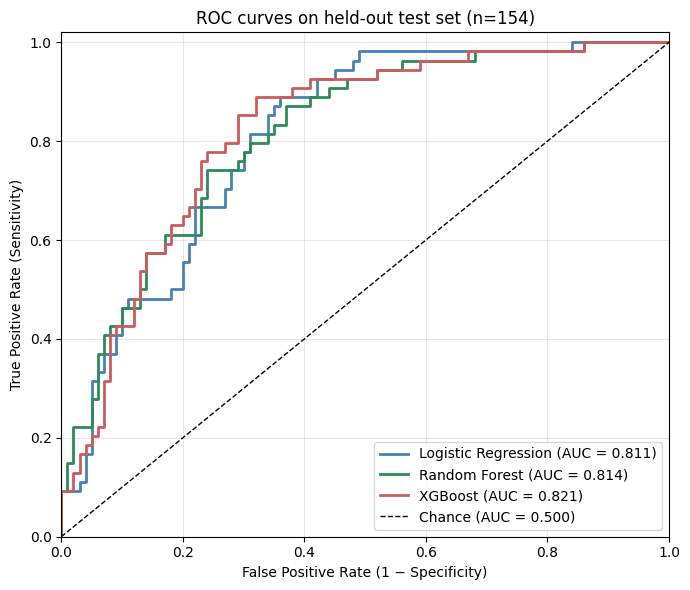

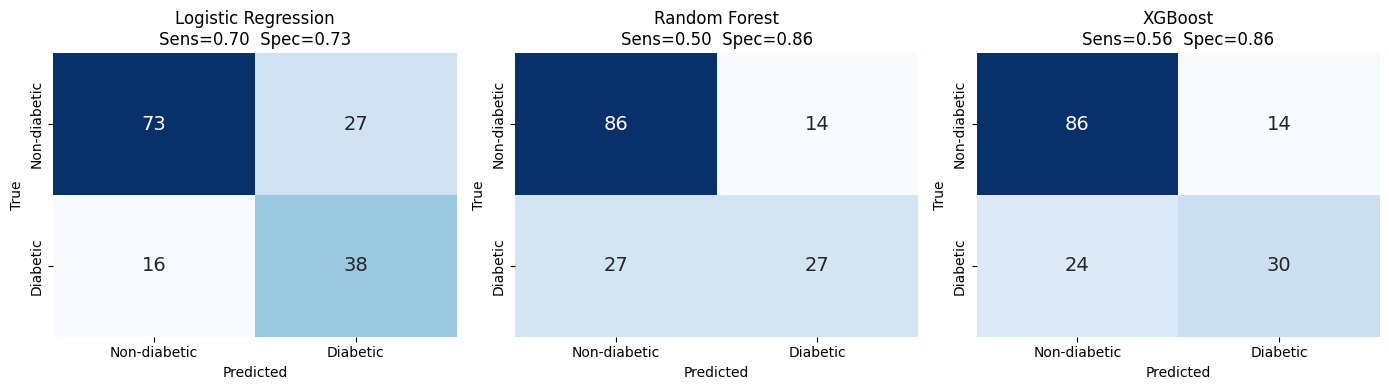

In [ ]:
# ============================================================
# CELL 7: Publication-quality figures for the report
# ============================================================
from sklearn.metrics import auc

# ---------- Figure: ROC curves for all three models ----------
plt.figure(figsize=(7, 6))
colors = {'Logistic Regression': 'steelblue',
          'Random Forest':       'seagreen',
          'XGBoost':              'indianred'}

for name, proba in roc_data.items():
    fpr, tpr, _ = roc_curve(y_test, proba)
    auc_val = auc(fpr, tpr)
    plt.plot(fpr, tpr, color=colors[name], lw=2,
             label=f'{name} (AUC = {auc_val:.3f})')

plt.plot([0, 1], [0, 1], 'k--', lw=1, label='Chance (AUC = 0.500)')
plt.xlim([0, 1]); plt.ylim([0, 1.02])
plt.xlabel('False Positive Rate (1 − Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC curves on held-out test set (n=154)')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('fig_roc.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Figure: Confusion matrices side-by-side ----------
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r in zip(axes, results):
    cm = np.array([[r['TN'], r['FP']], [r['FN'], r['TP']]])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Non-diabetic', 'Diabetic'],
                yticklabels=['Non-diabetic', 'Diabetic'],
                cbar=False, annot_kws={'size': 14})
    ax.set_title(f"{r['Model']}\nSens={r['Sensitivity']:.2f}  Spec={r['Specificity']:.2f}")
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
plt.tight_layout()
plt.savefig('fig_confusion.png', dpi=150, bbox_inches='tight')
plt.show()

# ---------- Figure: Logistic Regression coefficients (feature importance) ----------
# Since features are standardized, coefficients directly reflect each
# feature's re

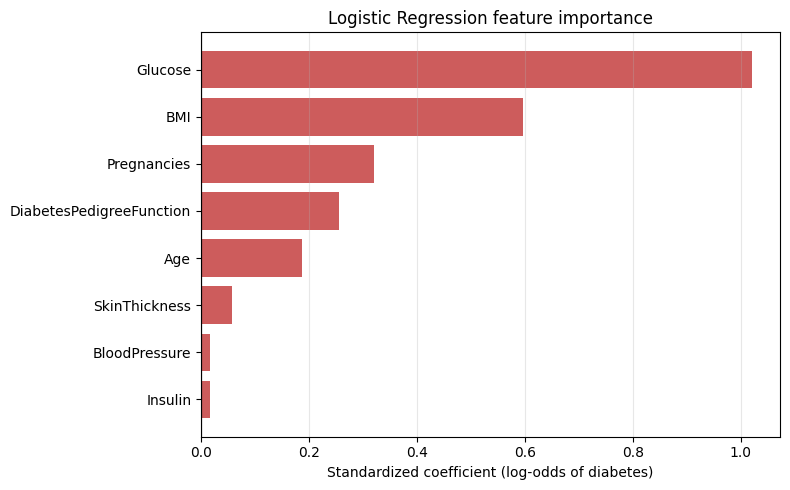


Logistic Regression standardized coefficients (sorted by magnitude):
Glucose                     1.022
BMI                         0.597
Pregnancies                 0.320
DiabetesPedigreeFunction    0.255
Age                         0.188
SkinThickness               0.057
BloodPressure               0.017
Insulin                     0.016
dtype: float64


In [ ]:
# ============================================================
# CELL 7b: Logistic Regression feature importance (standalone)
# ============================================================
best_lr = grid_lr.best_estimator_

# Since features are standardized, coefficients directly reflect each
# feature's relative contribution to the log-odds of diabetes.
coefs = pd.Series(best_lr.coef_[0], index=feature_names).sort_values()

plt.figure(figsize=(8, 5))
colors_bar = ['indianred' if c > 0 else 'steelblue' for c in coefs]
plt.barh(coefs.index, coefs.values, color=colors_bar)
plt.axvline(0, color='black', lw=0.8)
plt.xlabel('Standardized coefficient (log-odds of diabetes)')
plt.title('Logistic Regression feature importance')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig('fig_coefficients.png', dpi=150, bbox_inches='tight')
plt.show()

# Numerical values
print("\nLogistic Regression standardized coefficients (sorted by magnitude):")
print(coefs.reindex(coefs.abs().sort_values(ascending=False).index).round(3))

## Το Google Colab είναι διαθέσιμο στο VS Code!
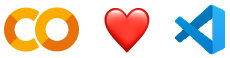

Δοκιμάστε τη νέα <a href="https://marketplace.visualstudio.com/items?itemName=Google.colab">επέκταση του Google Colab</a> για το Visual Studio Code. Μπορείτε να ξεκινήσετε με λίγα μόνο κλικ:

*  Στο VS Code, ανοίξτε την προβολή <strong><em>Επεκτάσεις</em></strong> και αναζητήστε το Google Colab για εγκατάσταση.
*  Ανοίξτε τον επιλογέα πυρήνα, δημιουργώντας ή ανοίγοντας οποιοδήποτε αρχείο σημειωματαρίου <code>.ipynb</code> στον τοπικό χώρο εργασίας σας, εκτελώντας ένα κελί ή κάνοντας κλικ στο κουμπί <strong><em>Επιλογή πυρήνα</em></strong> στην επάνω δεξιά γωνία.
*  Κάντε κλικ στην επιλογή <strong><em>Colab</em></strong> και, στη συνέχεια, επιλέξτε τον χρόνο εκτέλεσης &#40;runtime&#41; που επιθυμείτε, συνδεθείτε με τον Λογαριασμό σας Google και είστε έτοιμοι!

Δείτε περισσότερες λεπτομέρειες στο <a href="https://developers.googleblog.com/google-colab-is-coming-to-vs-code">ιστολόγιο ανακοινώσεων εδώ</a>.

## 🎁 Πρόγραμμα Pro χωρίς χρέωση για το Gemini και το Colab για φοιτητές τριτοβάθμιας εκπαίδευσης στις ΗΠΑ 🎓

Αποκτήστε μεγαλύτερη πρόσβαση στο πιο ακριβές μοντέλο μας, το Gemini 3 Pro, για προηγμένο προγραμματισμό, σύνθετη έρευνα και καινοτόμα έργα, με την υποστήριξη των εξειδικευμένων υπολογιστικών πόρων υψηλής απόδοσης του Colab για την επιστήμη των δεδομένων και τη μηχανική μάθηση.

Αποκτήστε την προσφορά Gemini χωρίς χρέωση στη διεύθυνση <a href="https://gemini.google/students?utm_source=colab&amp;utm_medium=banner&amp;utm_campaign=students_xpa_us-colab-banner">gemini.google/students</a>.  
Λάβετε την προσφορά Colab χωρίς χρέωση στη διεύθυνση <a href="https://colab.research.google.com/signup">colab.research.google.com/signup</a>.  
Ισχύουν όροι.

## Αποκτήστε πρόσβαση σε δημοφιλή μοντέλα AI μέσω του Google-Colab-AI χωρίς κλειδί API
Όλοι οι χρήστες έχουν πρόσβαση στα πιο δημοφιλή LLM μέσω της βιβλιοθήκης <code>google-colab-ai</code> Python, ενώ οι χρήστες επί πληρωμή έχουν πρόσβαση σε μεγαλύτερο εύρος μοντέλων. Για περισσότερες λεπτομέρειες, ανατρέξτε στην ενότητα <a href="https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/Getting_started_with_google_colab_ai.ipynb">έναρξη με το google colab ai</a>.



In [ ]:
from google.colab import ai
response = ai.generate_text("What is the capital of France?")

## Εξερευνήστε το Gemini API
Το Gemini API σας παρέχει πρόσβαση στα μοντέλα Gemini που δημιουργήθηκαν από το Google DeepMind. Τα μοντέλα Gemini έχουν σχεδιαστεί από την αρχή, ώστε να είναι πολυμεσικά, για να μπορείτε να βγάζετε συμπεράσματα απρόσκοπτα σε κείμενο, εικόνες, κώδικα και ήχο.

**Πώς να ξεκινήσετε;**
*  Μεταβείτε στο <a href="https://aistudio.google.com/">Google AI Studio</a> και συνδεθείτε με τον Λογαριασμό σας Google.
*  <a href="https://aistudio.google.com/app/apikey">Δημιουργήστε ένα κλειδί API</a>.
* Χρησιμοποιήστε τη γρήγορη εκκίνηση για <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started.ipynb">Python</a> ή καλέστε το REST API χρησιμοποιώντας το <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/rest/Prompting_REST.ipynb">curl</a>.

**Ανακαλύψτε τις προηγμένες δυνατότητες του Gemini**
*  Παίξτε με τις <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Image-out.ipynb">πολυμεσικές εξόδους</a> του Gemini, συνδυάζοντας κείμενο και εικόνες με επαναληπτικό τρόπο.
*  Ανακαλύψτε το <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_LiveAPI.ipynb">πολυμεσικό Live API</a> &#40;επίδειξη <a href="https://aistudio.google.com/live">εδώ</a>&#41;.
*  Μάθετε πώς μπορείτε να <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Spatial_understanding.ipynb&quot;">αναλύσετε εικόνες και να εντοπίσετε στοιχεία στις φωτογραφίες σας</a> χρησιμοποιώντας το Gemini &#40;μπόνους, υπάρχει και <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Spatial_understanding_3d.ipynb">τρισδιάστατη έκδοση</a>!&#41;.
*  Αξιοποιήστε τη δύναμη του <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/quickstarts/Get_started_thinking.ipynb">μοντέλου σκέψης Gemini</a>, το οποίο μπορεί να λύσει σύνθετες εργασίες με τις εσωτερικές του σκέψεις.
      
**Εξερεύνηση σύνθετων περιπτώσεων χρήσης**
*  Χρησιμοποιήστε τις <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Search_grounding_for_research_report.ipynb">δυνατότητες grounding του Gemini</a>, για να δημιουργήσετε μια αναφορά σχετικά με μια εταιρεία με βάση τα στοιχεία που μπορεί να βρει το μοντέλο στο διαδίκτυο.
*  Εξαγάγετε <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Pdf_structured_outputs_on_invoices_and_forms.ipynb">τιμολόγια και δεδομένα φόρμας από PDF</a> με δομημένο τρόπο.
*  Δημιουργήστε <a href="https://colab.research.google.com/github/google-gemini/cookbook/blob/main/examples/Book_illustration.ipynb">εικόνες με βάση ένα ολόκληρο βιβλίο</a> χρησιμοποιώντας το μεγάλο context window του Gemini και το Imagen.

Για να μάθετε περισσότερα, ανατρέξτε στο <a href="https://github.com/google-gemini/cookbook">cookbook του Gemini</a> ή επισκεφτείτε την <a href="https://ai.google.dev/docs/">τεκμηρίωση Gemini API</a>.


Το Colab διαθέτει πλέον λειτουργίες AI με την υποστήριξη του <a href="https://gemini.google.com">Gemini</a>. Το παρακάτω βίντεο παρέχει πληροφορίες σχετικά με τον τρόπο χρήσης αυτών των λειτουργιών, είτε χρησιμοποιείτε την Python για πρώτη φορά είτε είστε έμπειροι χρήστες.

<center>
  <a href="https://www.youtube.com/watch?v=V7RXyqFUR98" target="_blank">
  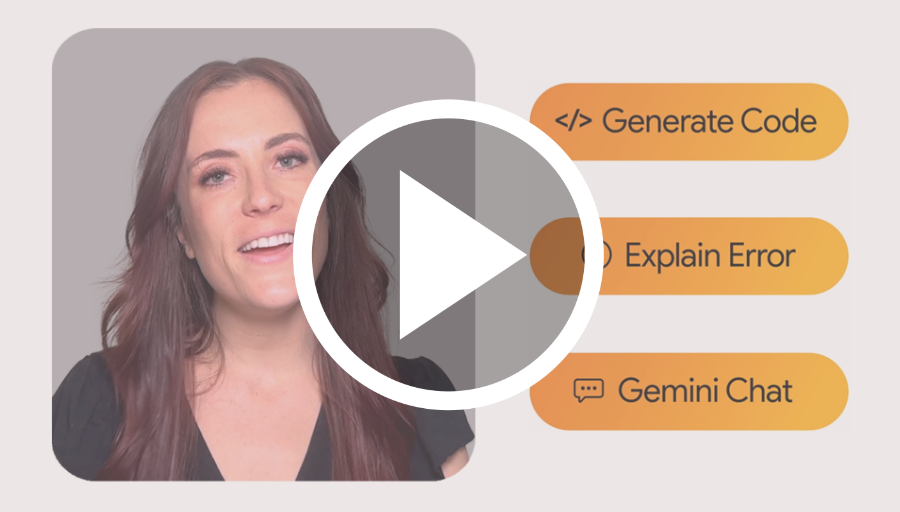
  </a>
</center>

<div class="markdown-google-sans">
  <h2>Τι είναι το Colab;</h2>
</div>

Το Colab, ή Colaboratory, σας επιτρέπει να γράφετε και να εκτελείτε κώδικα Python στο πρόγραμμα περιήγησής σας, με
- Μηδενική διαμόρφωση
- Πρόσβαση χωρίς χρέωση σε GPU
- Εύκολη κοινοποίηση

Είτε είστε <strong>φοιτητής</strong>, είτε <strong>επιστήμονας δεδομένων</strong> είτε <strong>ερευνητής AI</strong>, το Colab μπορεί να κάνει την εργασία σας πιο εύκολη. Παρακολουθήστε την <a href="https://www.youtube.com/watch?v=inN8seMm7UI">Εισαγωγή στο Colab</a> ή τις <a href="https://www.youtube.com/watch?v=rNgswRZ2C1Y">Λειτουργίες του Colab που μπορεί να μην γνωρίζετε</a> για να μάθετε περισσότερα ή ξεκινήστε παρακάτω!

<div class="markdown-google-sans">

## <strong>Έναρξη χρήσης</strong>
</div>

Το έγγραφο που διαβάζετε δεν είναι στατική ιστοσελίδα, αλλά ένα διαδραστικό περιβάλλον που ονομάζεται <strong>σημειωματάριο Colab</strong> το οποίο σας επιτρέπει να γράφετε και να εκτελείτε κώδικα.

Για παράδειγμα, εδώ βλέπετε ένα <strong>κελί κώδικα</strong> με ένα σύντομο σενάριο Python το οποίο υπολογίζει μια τιμή, την αποθηκεύει σε μια μεταβλητή και προβάλλει το αποτέλεσμα:

In [ ]:
seconds_in_a_day = 24 * 60 * 60
seconds_in_a_day

86400

Για να εκτελέσετε τον κώδικα στο παραπάνω κελί, επιλέξτε το με ένα κλικ και είτε πιέστε το κουμπί αναπαραγωγής στα αριστερά του κώδικα είτε χρησιμοποιήστε τη συντόμευση πληκτρολογίου Command/Ctrl+Enter. Για να επεξεργαστείτε τον κώδικα, απλώς κάντε κλικ στο κελί και ξεκινήστε την επεξεργασία.

Οι μεταβλητές που ορίζετε σε ένα κελί μπορούν να χρησιμοποιηθούν αργότερα σε άλλα κελιά:

In [ ]:
seconds_in_a_week = 7 * seconds_in_a_day
seconds_in_a_week

604800

Τα σημειωματάρια Colab σας επιτρέπουν να συνδυάζετε <strong>εκτελέσιμο κώδικα</strong> και <strong>εμπλουτισμένο κείμενο</strong> σε ένα έγγραφο, μαζί με <strong>εικόνες</strong>, <strong>HTML</strong>, <strong>LaTeX</strong> κ.ά. Όταν δημιουργείτε τα δικά σας σημειωματάρια Colab, αυτά αποθηκεύονται στον λογαριασμό σας στο Google Drive. Μπορείτε εύκολα να κοινοποιήσετε τα σημειωματάρια Colab σε συνεργάτες ή φίλους, επιτρέποντάς τους να τα σχολιάσουν ή να κάνουν αλλαγές. Για να μάθετε περισσότερα, ανατρέξτε στην ενότητα <a href="/notebooks/basic_features_overview.ipynb">Επισκόπηση του Colab</a>. Για να δημιουργήσετε ένα νέο σημειωματάριο Colab μπορείτε να χρησιμοποιήσετε το μενού Αρχείο παραπάνω ή να χρησιμοποιήσετε τον ακόλουθο σύνδεσμο: <a href="http://colab.research.google.com#create=true">δημιουργία νέου σημειωματαρίου Colab</a>.

Τα σημειωματάρια Colab είναι σημειωματάρια Jupyter που φιλοξενούνται στο Colab. Για να μάθετε περισσότερα σχετικά με το έργο Jupyter, ανατρέξτε στη διεύθυνση <a href="https://www.jupyter.org">jupyter.org</a>.

<div class="markdown-google-sans">

## Επιστήμη των δεδομένων
</div>

Με το Colab μπορείτε να αξιοποιήσετε πλήρως την ισχύ των δημοφιλών βιβλιοθηκών Python για την ανάλυση και την οπτικοποίηση των δεδομένων. Το παρακάτω κελί κώδικα χρησιμοποιεί το στοιχείο <strong>numpy</strong> για να δημιουργήσει ορισμένα τυχαία δεδομένα και χρησιμοποιεί το στοιχείο <strong>matplotlib</strong> για να τα οπτικοποιήσει. Για να επεξεργαστείτε τον κώδικα, απλώς κάντε κλικ στο κελί και ξεκινήστε την επεξεργασία.

Μπορείτε να εισαγάγετε τα δικά σας δεδομένα στα σημειωματάρια Colab από τον λογαριασμό σας στο Google Drive, συμπεριλαμβανομένων των δεδομένων υπολογιστικών φύλλων καθώς και από το GitHub και από πολλές άλλες πηγές. Για να μάθετε περισσότερα σχετικά με την εισαγωγή δεδομένων και τον τρόπο χρήσης του Colab στην επιστήμη των δεδομένων, ανατρέξτε στους παρακάτω συνδέσμους, στην ενότητα <a href="#working-with-data">Εργασία με δεδομένα</a>.

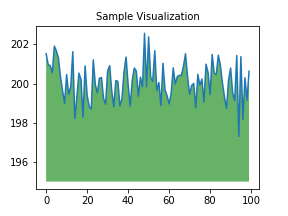

In [ ]:
import numpy as np
import IPython.display as display
from matplotlib import pyplot as plt
import io
import base64

ys = 200 + np.random.randn(100)
x = [x for x in range(len(ys))]

fig = plt.figure(figsize=(4, 3), facecolor='w')
plt.plot(x, ys, '-')
plt.fill_between(x, ys, 195, where=(ys > 195), facecolor='g', alpha=0.6)
plt.title("Sample Visualization", fontsize=10)

data = io.BytesIO()
plt.savefig(data)
image = F"data:image/png;base64,{base64.b64encode(data.getvalue()).decode()}"
alt = "Sample Visualization"
display.display(display.Markdown(F"""![{alt}]({image})"""))
plt.close(fig)

Τα σημειωματάρια Colab εκτελούν κώδικα στους διακομιστές cloud της Google, κάτι που σημαίνει ότι μπορείτε να αξιοποιήσετε τη δύναμη του εξοπλισμού της Google, συμπεριλαμβανομένων των <a href="#using-accelerated-hardware">GPU και των TPU</a>, ανεξάρτητα από την ισχύ του δικού σας μηχανήματος. Το μόνο που χρειάζεστε είναι ένα πρόγραμμα περιήγησης.

Για παράδειγμα, αν περιμένετε να ολοκληρωθεί η εκτέλεση του κώδικα <strong>pandas</strong> και θέλετε να επιταχύνετε τη διαδικασία, μπορείτε να μεταβείτε σε χρόνο εκτέλεσης &#40;runtime&#41; GPU και να χρησιμοποιήσετε βιβλιοθήκες όπως το <a href="https://rapids.ai/cudf-pandas">RAPIDS cuDF</a> που παρέχουν επιτάχυνση χωρίς αλλαγή κώδικα.

Για να μάθετε περισσότερα σχετικά με την επιτάχυνση του pandas στο Colab, ανατρέξτε στον <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_colab_demo.ipynb">οδηγό 10 λεπτών</a> ή
 στην <a href="https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cudf_pandas_stocks_demo.ipynb">επίδειξη ανάλυσης δεδομένων χρηματιστηρίου των ΗΠΑ</a>.

<div class="markdown-google-sans">

## Μηχανική εκμάθηση
</div>

Με το Colab, μπορείτε να εισαγάγετε ένα σύνολο δεδομένων μιας εικόνας, να εκπαιδεύσετε έναν κατηγοριοποιητή εικόνων σε αυτό και να αξιολογήσετε το μοντέλο, χρησιμοποιώντας μόνο <a href="https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/quickstart/beginner.ipynb">λίγες γραμμές κώδικα</a>.

Το Colab χρησιμοποιείται πολύ στην κοινότητα μηχανικής εκμάθησης σε διάφορες εφαρμογές, όπως είναι οι εξής:
- Έναρξη χρήσης του TensorFlow
- Ανάπτυξη και εκπαίδευση νευρωνικών δικτύων
- Πειραματισμοί με TPU
- Διάδοση έρευνας AI
- Δημιουργία οδηγών

Για να δείτε ένα δείγμα σημειωματαρίων Colab που επιδεικνύουν τις εφαρμογές μηχανικής εκμάθησης, ανατρέξτε στα παρακάτω <a href="#machine-learning-examples">παραδείγματα μηχανικής εκμάθησης</a>.

<div class="markdown-google-sans">

## Περισσότεροι πόροι

### Εργασία με σημειωματάρια στο Colab

</div>

- [Επισκόπηση του Colab](/notebooks/basic_features_overview.ipynb)
- [Οδηγός για Markdown](/notebooks/markdown_guide.ipynb)
- [Εισαγωγή βιβλιοθηκών και εγκατάσταση εξαρτήσεων](/notebooks/snippets/importing_libraries.ipynb)
- [Αποθήκευση και φόρτωση σημειωματαρίων στο GitHub](https://colab.research.google.com/github/googlecolab/colabtools/blob/main/notebooks/colab-github-demo.ipynb)
- [Διαδραστικές φόρμες](/notebooks/forms.ipynb)
- [Διαδραστικά γραφικά στοιχεία](/notebooks/widgets.ipynb)

<div class="markdown-google-sans">

<a name="working-with-data"></a>
### Εργασία με δεδομένα
</div>

- [Φόρτωση δεδομένων: Drive, Υπολογιστικά φύλλα και Google Cloud Storage](/notebooks/io.ipynb)
- [Γραφήματα: οπτικοποίηση δεδομένων](/notebooks/charts.ipynb)
- [Έναρξη χρήσης του BigQuery](/notebooks/bigquery.ipynb)

<div class="markdown-google-sans">

### Μηχανική μάθηση

<div>

Αυτά είναι μερικά από τα σημειωματάρια που σχετίζονται με τη μηχανική μάθηση, συμπεριλαμβανομένης της διαδικτυακής σειράς μαθημάτων μηχανικής μάθησης της Google. Μεταβείτε στον <a href="https://developers.google.com/machine-learning/crash-course/">πλήρη ιστότοπο σειράς μαθημάτων</a> για περισσότερα.
- [Εισαγωγή στις δομές DataFrame της Pandas](https://colab.research.google.com/github/google/eng-edu/blob/main/ml/cc/exercises/pandas_dataframe_ultraquick_tutorial.ipynb)
- [Εισαγωγή στο RAPIDS cuDF για επιτάχυνση των panda](https://nvda.ws/rapids-cudf)
- [Έναρξη με τη λειτουργία επιτάχυνσης του cuML](https://colab.research.google.com/github/rapidsai-community/showcase/blob/main/getting_started_tutorials/cuml_sklearn_colab_demo.ipynb)

<div class="markdown-google-sans">

<a name="using-accelerated-hardware"></a>
### Χρήση εξοπλισμού με επιτάχυνση
</div>

- [Εκπαιδεύστε ένα CNN για την ταξινόμηση χειρόγραφων ψηφίων στο σύνολο δεδομένων MNIST χρησιμοποιώντας το Flax NNX API](https://colab.research.google.com/github/google/flax/blob/main/docs_nnx/mnist_tutorial.ipynb)
- [Εκπαίδευση Vision Transformer &#40;ViT&#41; για ταξινόμηση εικόνων με τη χρήση JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_Vision_transformer.ipynb)
- [Ταξινόμηση κειμένου με ένα γλωσσικό μοντέλο transformer με τη χρήση JAX](https://colab.research.google.com/github/jax-ml/jax-ai-stack/blob/main/docs/source/JAX_transformer_text_classification.ipynb)

<div class="markdown-google-sans">

<a name="machine-learning-examples"></a>

### Παραδείγματα

</div>

- <a href="https://docs.jaxstack.ai/en/latest/JAX_for_LLM_pretraining.html">Εκπαίδευση γλωσσικού μοντέλου miniGPT με τη στοίβα AI JAX</a>
- <a href="https://github.com/google/tunix/blob/main/examples/qlora_gemma.ipynb">Λεπτομερής ρύθμιση LoRA/QLoRA για LLM με τη χρήση Tunix</a>
- <a href="https://keras.io/examples/keras_recipes/parameter_efficient_finetuning_of_gemma_with_lora_and_qlora/">Λεπτομερής ρύθμιση βάσει αποδοτικότητας παραμέτρων &#40;PEFT&#41; του Gemma με LoRA και QLoRA</a>
- <a href="https://keras.io/keras_hub/guides/hugging_face_keras_integration/">Φόρτωση σημείων ελέγχου Transformer του Hugging Face</a>
- <a href="https://keras.io/guides/int8_quantization_in_keras/">Κβαντοποίηση ακέραιων 8 bit στο Keras</a>
- <a href="https://keras.io/examples/keras_recipes/float8_training_and_inference_with_transformer/">Εκπαίδευση και εξαγωγή συμπερασμάτων Float8 με ένα απλό μοντέλο Transformer</a>
- <a href="https://keras.io/keras_hub/guides/transformer_pretraining/">Προεκπαίδευση ενός Transformer από την αρχή με το KerasHub</a>
- <a href="https://keras.io/examples/vision/mnist_convnet/">Απλό convnet MNIST</a>
- <a href="https://keras.io/examples/vision/image_classification_from_scratch/">Ταξινόμηση εικόνων από την αρχή με χρήση του Keras 3</a>
- <a href="https://keras.io/keras_hub/guides/classification_with_keras_hub/">Ταξινόμηση εικόνων με το KerasHub</a>
